## 1. Veri Kaynaklarının Tanımlanması ve Yüklenmesi

Bu modülde, çalışmada kullanılan küresel havalimanı ve uçuş verileri OpenFlights açık veri setinden çevrim içi olarak temin edilmiştir.
airports.dat dosyası havalimanlarına ait konumsal ve tanımlayıcı bilgileri, routes.dat dosyası ise havalimanları arasındaki tarifeli uçuş bağlantılarını içermektedir.
Veriler analiz ortamına yüklendikten sonra, veri setlerinin boyutları kontrol edilerek ham veri yapısı gözlemlenmiştir.

In [1]:
import pandas as pd
import networkx as nx

airports_url = "https://raw.githubusercontent.com/jpatokal/openflights/master/data/airports.dat"
routes_url   = "https://raw.githubusercontent.com/jpatokal/openflights/master/data/routes.dat"

airports_cols = [
    "airport_id","name","city","country",
    "iata","icao","lat","lon",
    "altitude","timezone","dst",
    "tz_db","type","source"
]

routes_cols = [
    "airline","airline_id",
    "src_iata","src_id",
    "dst_iata","dst_id",
    "codeshare","stops","equipment"
]

airports = pd.read_csv(airports_url, names=airports_cols, header=None)
routes   = pd.read_csv(routes_url,   names=routes_cols,   header=None)

print("Airports:", airports.shape)
print("Routes:", routes.shape)


Airports: (7698, 14)
Routes: (67663, 9)


## 2. Veri Temizleme ve Filtreleme

Bu modülde ağ analizinin sağlıklı biçimde gerçekleştirilebilmesi için veri setine ön işleme adımları uygulanmıştır.
IATA kodu bulunmayan havalimanları ve kaynak ya da hedef bilgisi eksik olan uçuş rotaları analiz dışı bırakılmıştır.
Ayrıca ağ düğümlerinin standart biçimde temsil edilebilmesi amacıyla yalnızca üç harfli IATA kodlarına sahip havalimanları dikkate alınmıştır.

In [2]:
airports = airports.dropna(subset=["iata"])
routes   = routes.dropna(subset=["src_iata", "dst_iata"])


airports = airports[airports["iata"].str.len() == 3]

print("Temiz airports:", airports.shape)
print("Temiz routes:", routes.shape)


Temiz airports: (6072, 14)
Temiz routes: (67663, 9)


## 3. Yönlü Havalimanı Ağının Oluşturulması

Bu modülde küresel havalimanı - uçuş sistemi yönlü bir ağ olarak modellenmiştir.
Her bir havalimanı bir düğüm (node), havalimanları arasındaki tarifeli uçuşlar ise yönlü kenarlar (edge) olarak tanımlanmıştır.
Bu soyutlama ile ağın fiziksel ayrıntılarından ziyade bağlantı yapısı ve düğümler arası ilişkiler analiz edilmiştir.

In [3]:
G = nx.DiGraph()

# Düğümler
for iata in airports["iata"]:
    G.add_node(iata)

# Kenarlar
for _, row in routes.iterrows():
    if row["src_iata"] in G and row["dst_iata"] in G:
        G.add_edge(row["src_iata"], row["dst_iata"])

print("Node sayısı:", G.number_of_nodes())
print("Edge sayısı:", G.number_of_edges())


Node sayısı: 6072
Edge sayısı: 37042


## 4. Merkezilik Ölçütlerinin Hesaplanması

Bu modülde ağın yapısal özelliklerini incelemek amacıyla derece (degree), aradalık (betweenness) ve yakınlık (closeness) merkezilik ölçütleri hesaplanmıştır.
Bu ölçütler, havalimanlarının ağ içindeki yerel bağlantı yoğunluğunu, köprü rolünü ve genel erişilebilirliğini temsil etmektedir.

In [4]:
degree_c   = nx.degree_centrality(G)
between_c  = nx.betweenness_centrality(G)
close_c    = nx.closeness_centrality(G)

results = pd.DataFrame({
    "Airport": list(degree_c.keys()),
    "Degree": list(degree_c.values()),
    "Betweenness": list(between_c.values()),
    "Closeness": list(close_c.values())
})

results_sorted = results.sort_values(by="Betweenness", ascending=False)
results_sorted.to_csv("../outputs/centrality_results.csv", index=False)


## 5. Betweenness Centrality’ye Göre Coğrafi Görselleştirme

Bu modülde aradalık merkeziliği değerleri coğrafi olarak görselleştirilmiştir.
Betweenness değerleri sayısal olarak çok küçük olduğundan, yalnızca görsel okunabilirliği artırmak amacıyla ölçeklendirilmiştir.
Haritada düğümlerin renk ve boyutları, havalimanlarının ağ üzerindeki köprü rolünü temsil etmektedir.


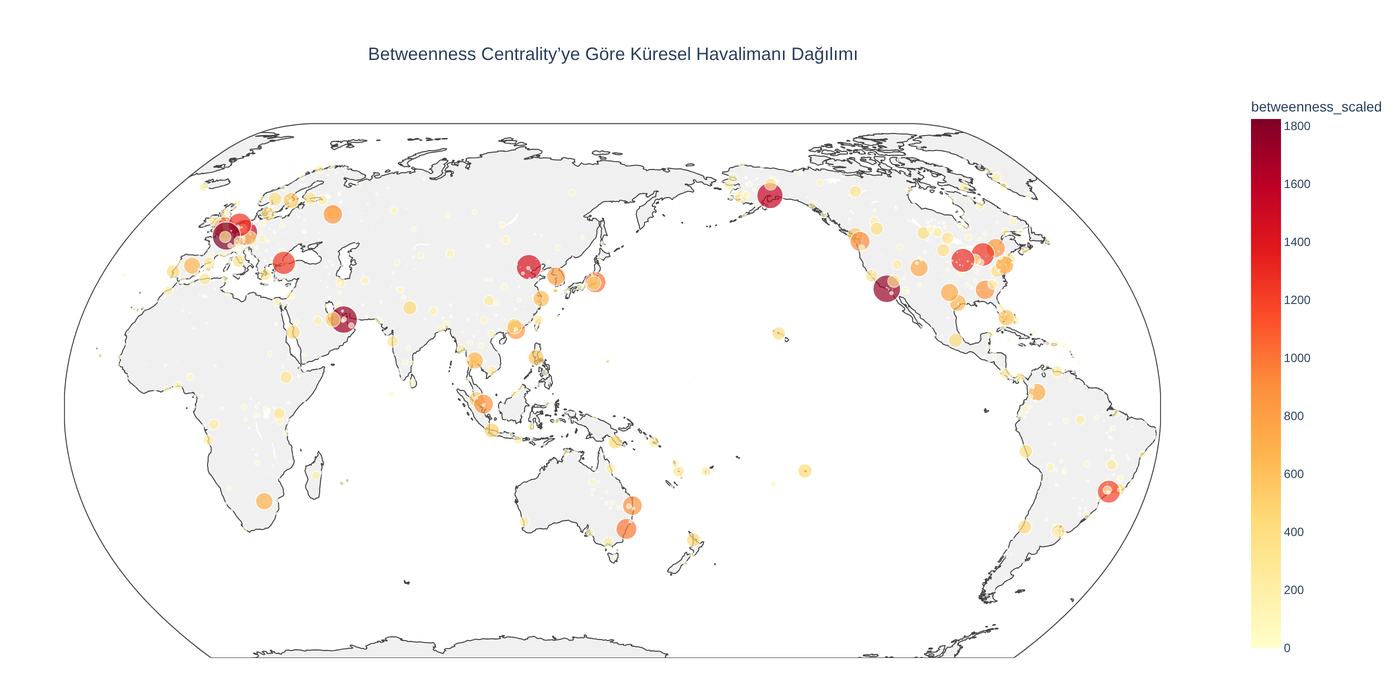

In [5]:
import plotly.express as px

viz_df = airports.merge(
    results_sorted,
    left_on="iata",
    right_on="Airport",
    how="inner"
)


viz_df["betweenness_scaled"] = viz_df["Betweenness"] * 1e5

viz_df.head()
fig = px.scatter_geo(
    viz_df,
    lat="lat",
    lon="lon",
    color="betweenness_scaled",
    size="betweenness_scaled",
    hover_name="iata",
    hover_data={
        "name": True,
        "country": True,
        "Degree": True,
        "Betweenness": ':.6f',
        "Closeness": ':.6f',
        "lat": False,
        "lon": False,
        "betweenness_scaled": False
    },
    projection="natural earth",
    color_continuous_scale="YlOrRd",

)

fig.update_layout(
    geo=dict(
        showland=True,
        landcolor="rgb(240,240,240)"
    ),
    margin=dict(l=0, r=0, t=80, b=0),
    height=650,
    annotations=[
        dict(
            text="Betweenness Centrality’ye Göre Küresel Havalimanı Dağılımı",
            x=0.5,
            y=1.08,
            xref="paper",
            yref="paper",
            showarrow=False,
            font=dict(size=18)
        )
    ]
)



fig.show()


## 6. Degree Centrality’ye Göre Coğrafi Görselleştirme

Bu modülde havalimanlarının doğrudan bağlantı yoğunluğu degree merkeziliği aracılığıyla görselleştirilmiştir.
Daha fazla bağlantıya sahip olan havalimanları, harita üzerinde daha büyük ve daha yoğun renklerle temsil edilmiştir.

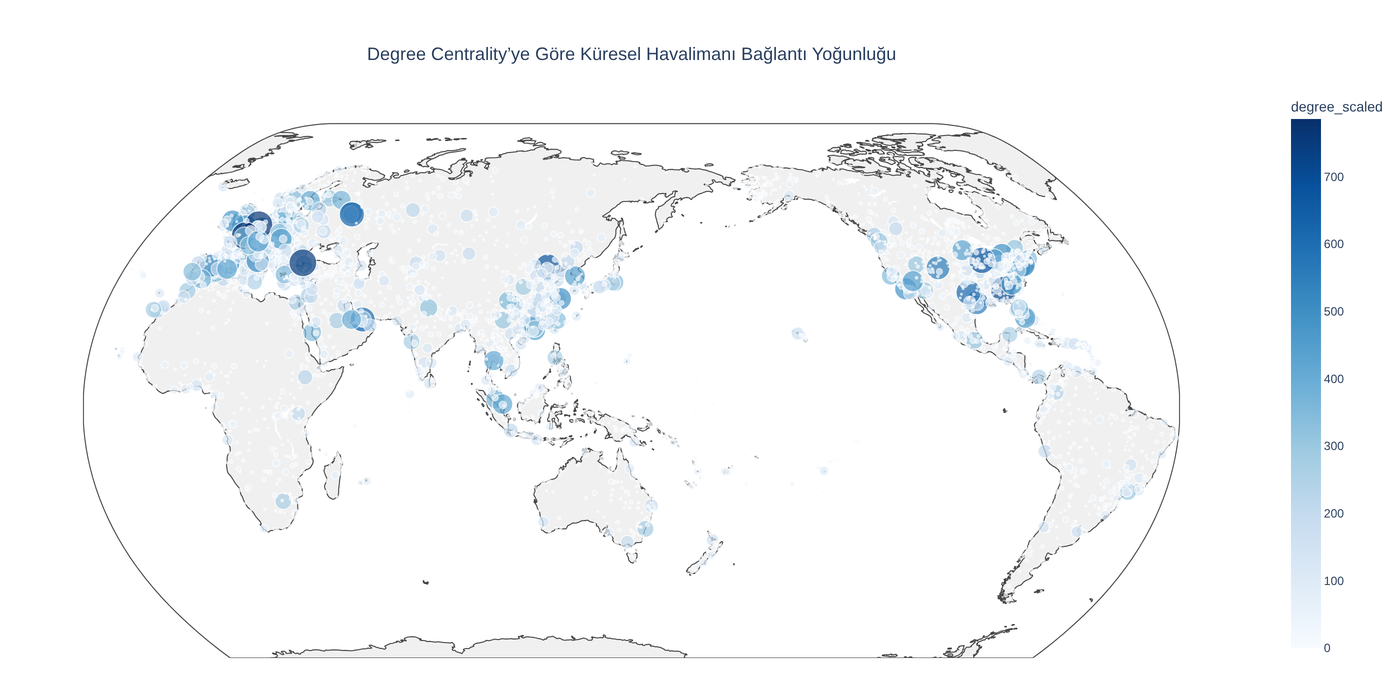

In [6]:
degree_df = airports.merge(
    results_sorted,
    left_on="iata",
    right_on="Airport",
    how="inner"
)


degree_df["degree_scaled"] = degree_df["Degree"] * 1e4

fig_degree = px.scatter_geo(
    degree_df,
    lat="lat",
    lon="lon",
    size="degree_scaled",
    color="degree_scaled",
    projection="natural earth",
    color_continuous_scale="Blues",
    hover_name="iata",
    hover_data={
        "name": True,
        "country": True,
        "Degree": ':.6f',
        "Betweenness": ':.6f',
        "Closeness": ':.6f',
        "lat": False,
        "lon": False,
        "degree_scaled": False
    },

)

fig_degree.update_layout(
    geo=dict(
        showland=True,
        landcolor="rgb(240,240,240)"
    ),
    margin=dict(l=0, r=0, t=80, b=0),
    height=650,
    annotations=[
        dict(
            text="Degree Centrality’ye Göre Küresel Havalimanı Bağlantı Yoğunluğu",
            x=0.5,
            y=1.08,
            xref="paper",
            yref="paper",
            showarrow=False,
            font=dict(size=18)
        )
    ]
)


fig_degree.show()


## 7. Closeness Centrality’ye Göre Coğrafi Görselleştirme

Bu modülde havalimanlarının ağ genelindeki erişilebilirliği closeness merkeziliği kullanılarak görselleştirilmiştir.
Bu haritada yalnızca renk kodlaması kullanılarak, havalimanlarının ağın geneline olan topolojik yakınlığı vurgulanmıştır. Haritada kullanılan renk skalası, havalimanlarının closeness merkeziliği değerlerini temsil etmektedir. Açık tonlar ağın topolojik merkezine yakın ve erişilebilirliği yüksek düğümleri, koyu tonlar ise ağın periferisinde yer alan ve erişilebilirliği düşük havalimanlarını göstermektedir.

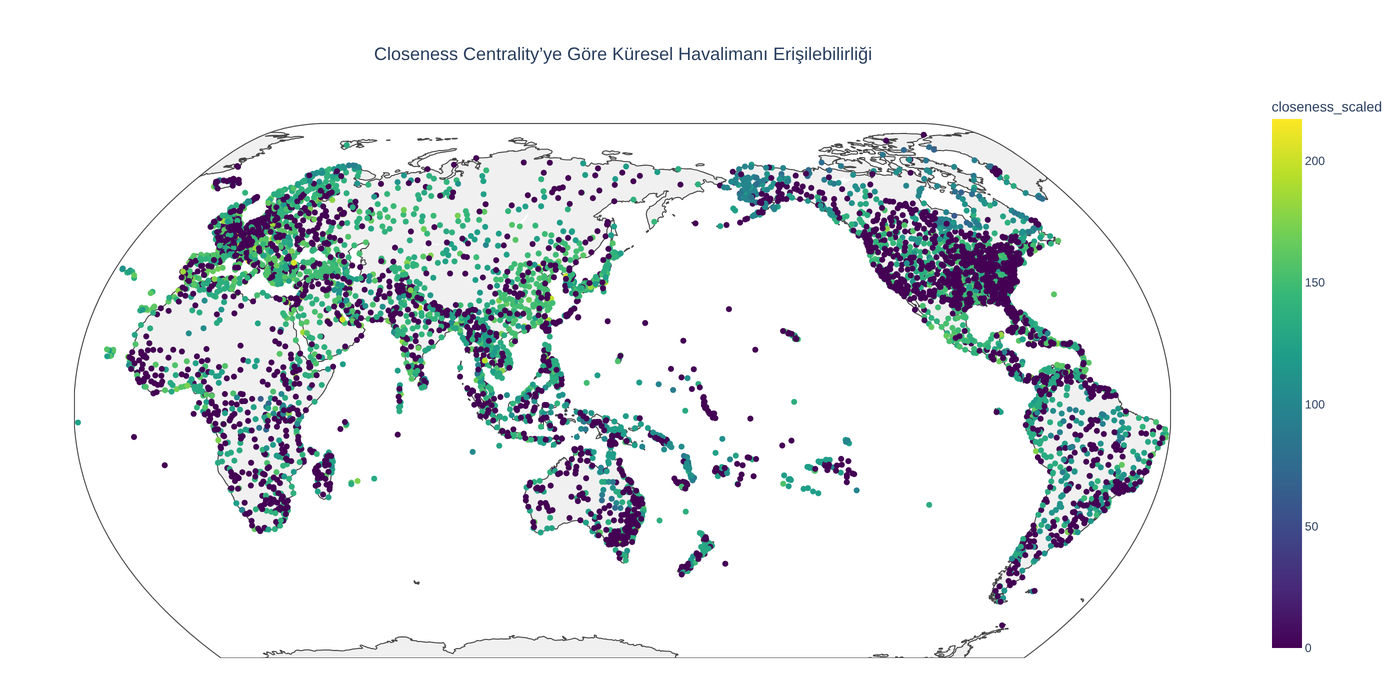

In [7]:
close_df = airports.merge(
    results_sorted,
    left_on="iata",
    right_on="Airport",
    how="inner"
)


close_df["closeness_scaled"] = close_df["Closeness"] * 1e3

fig_close = px.scatter_geo(
    close_df,
    lat="lat",
    lon="lon",
    color="closeness_scaled",
    projection="natural earth",
    color_continuous_scale="Viridis",
    hover_name="iata",
    hover_data={
        "name": True,
        "country": True,
        "Degree": ':.6f',
        "Betweenness": ':.6f',
        "Closeness": ':.6f',
        "lat": False,
        "lon": False,
        "closeness_scaled": False
    },
)

fig_close.update_layout(
    geo=dict(
        showland=True,
        landcolor="rgb(240,240,240)"
    ),
    margin=dict(l=0, r=0, t=80, b=0),
    height=650,
    annotations=[
        dict(
            text="Closeness Centrality’ye Göre Küresel Havalimanı Erişilebilirliği",
            x=0.5,
            y=1.08,
            xref="paper",
            yref="paper",
            showarrow=False,
            font=dict(size=18)
        )
    ]
)

fig_close.show()


## 8. Merkezilik Sıralamaları ve Ek CSV Dosyası

Bu modülde tüm havalimanları için hesaplanan merkezilik değerleri sıralanmış ve ekler bölümünde sunulmak üzere CSV formatında dışa aktarılmıştır.
Bu tablo, ağ üzerindeki düğümlerin farklı merkezilik ölçütlerine göre karşılaştırılmasına olanak tanımaktadır.


In [8]:
df = pd.read_csv("../outputs/centrality_results.csv")


table_20 = df.head(21)


table_20 = table_20[["Airport", "Degree", "Betweenness", "Closeness"]]


table_20[["Degree", "Betweenness", "Closeness"]] = table_20[
    ["Degree", "Betweenness", "Closeness"]
].round(4)

table_20


degree_rank = (
    results.sort_values(by="Degree", ascending=False)
    .reset_index(drop=True)
)
degree_rank["Degree_Rank"] = degree_rank.index + 1


betweenness_rank = (
    results.sort_values(by="Betweenness", ascending=False)
    .reset_index(drop=True)
)
betweenness_rank["Betweenness_Rank"] = betweenness_rank.index + 1


closeness_rank = (
    results.sort_values(by="Closeness", ascending=False)
    .reset_index(drop=True)
)
closeness_rank["Closeness_Rank"] = closeness_rank.index + 1
full_rank_table = (
    results[["Airport", "Degree", "Betweenness", "Closeness"]]
    .merge(degree_rank[["Airport", "Degree_Rank"]], on="Airport")
    .merge(betweenness_rank[["Airport", "Betweenness_Rank"]], on="Airport")
    .merge(closeness_rank[["Airport", "Closeness_Rank"]], on="Airport")
)
full_rank_table.to_csv(
    "../outputs/Appendix_B_All_Airports_Centrality_Rankings.csv",
    index=False
)


